# Кривая доходности ОФЗ и риск портфеля облигаций

Ноутбук проходит все шаги проекта на реальных данных Мосбиржи:

1. **Данные** — котировки ОФЗ-ПД и купонные графики из ISS API, проверка собственных расчётов против биржевых.
2. **Кривая** — модель Нельсона-Сигеля: «в лоб» по доходностям и правильно, как бескупонная кривая по ценам; сравнение с КБД Мосбиржи.
3. **Риск** — дюрация, выпуклость, DV01 каждой бумаги; портфель из 5 ОФЗ; сценарии сдвига и наклона кривой; разложение риска по ключевым срокам.
4. **История** — как кривая сдвигалась вокруг решений Банка России в 2024–2026 годах.

Все данные уже лежат в `data/`, поэтому ноутбук работает без интернета. Чтобы докачать новые даты, создайте `MoexData()` без `offline=True` — недостающее скачается из ISS и допишется в кэш.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ofz").is_dir())
sys.path.insert(0, str(ROOT))   # корень репозитория: запуск хоть из notebooks/, хоть из корня

import numpy as np
import pandas as pd

from ofz import history, plots, risk
from ofz.market import MarketSnapshot
from ofz.moex import MoexData

pd.set_option("display.precision", 2)
data = MoexData(ROOT / "data", offline=True)
DATE = "2026-10-07"   # последний полный торговый день в кэше

## 1. Данные

Берём итоги торгов всеми ОФЗ-ПД (серии 25xxx и 26xxx) в режиме TQOB и полные купонные графики выпусков. Оставляем бумаги со сроком от 3 месяцев и оборотом от 1 млн руб. за день: у самых коротких доходность прыгает от каждого тика цены, у неторгуемых цена устаревшая.

Важная деталь: расчёты по ОФЗ идут **T+1**, а поле `ACCINT` в истории ISS — это НКД на дату *торгов*. Если сложить цену с этим НКД, доходность разойдётся с биржевой примерно на 1 б.п. Поэтому НКД пересчитываем сами на дату расчётов.

In [2]:
snap = MarketSnapshot.load(DATE, data)
print(f"{DATE}: {len(snap.table)} выпусков, дата расчётов {snap.settle}")

view = snap.table.assign(
    ytm=snap.table.ytm * 100, ytm_moex=snap.table.ytm_moex * 100,
    diff_bp=(snap.table.ytm - snap.table.ytm_moex) * 1e4,
    maturity=snap.table.maturity.dt.strftime("%d.%m.%Y"),
)[["name", "maturity", "years", "coupon", "price", "accint", "ytm", "ytm_moex", "diff_bp", "macaulay", "value_mln"]]
view.columns = ["Выпуск", "Погашение", "Лет", "Купон, %", "Цена, %", "НКД, руб.", "YTM, %",
                "YTM биржи, %", "Разница, б.п.", "Дюрация, лет", "Оборот, млн"]
view.round(2)

2026-10-07: 30 выпусков, дата расчётов 2026-10-08


,Выпуск,Погашение,Лет,"Купон, %","Цена, %","НКД, руб.","YTM, %","YTM биржи, %","Разница, б.п.","Дюрация, лет","Оборот, млн"
0,ОФЗ 26207,03.02.2027,0.32,8.15,98.87,14.29,12.09,12.09,-0.25,0.32,334.6
1,ОФЗ 26232,06.10.2027,0.99,6.00,93.91,0.16,13.12,13.12,-0.27,0.98,179.7
2,ОФЗ 26212,19.01.2028,1.28,7.05,92.60,15.06,13.96,13.96,-0.17,1.23,167.9
3,ОФЗ 26236,17.05.2028,1.61,5.70,88.24,22.02,14.62,14.62,-0.45,1.52,465.0
4,ОФЗ 26237,14.03.2029,2.43,6.70,84.56,4.04,14.97,14.97,-0.30,2.26,197.1
5,ОФЗ 26224,23.05.2029,2.62,6.90,84.19,25.33,14.84,14.84,0.17,2.36,55.9
6,ОФЗ 26242,29.08.2029,2.89,9.00,87.66,8.88,14.87,14.87,-0.27,2.56,728.6
7,ОФЗ 26228,10.04.2030,3.51,7.65,80.78,36.89,15.44,15.44,-0.44,2.96,424.8
8,ОФЗ 26251,28.08.2030,3.89,9.50,84.15,9.37,15.58,15.58,0.04,3.25,107.8
9,ОФЗ 26235,12.03.2031,4.43,5.90,71.20,3.56,15.60,15.60,0.50,3.84,23.9


In [3]:
diff = (snap.table.ytm - snap.table.ytm_moex).abs() * 1e4
print(f"Наша доходность против биржевой: медиана {diff.median():.2f} б.п., максимум {diff.max():.2f} б.п.")
print("Биржа публикует доходность с шагом 0,01 % = 1 б.п., так что это совпадение до округления.")

Наша доходность против биржевой: медиана 0.26 б.п., максимум 0.50 б.п.
Биржа публикует доходность с шагом 0,01 % = 1 б.п., так что это совпадение до округления.


## 2. Кривая: Нельсон-Сигель

$$z(t) = \beta_0 + \beta_1\,\frac{1-e^{-t/\tau}}{t/\tau} + \beta_2\left(\frac{1-e^{-t/\tau}}{t/\tau} - e^{-t/\tau}\right)$$

$\beta_0$ — уровень длинных ставок, $\beta_0+\beta_1$ — ставка на коротком конце, $\beta_2$ — «горб» (кривизна), $\tau$ — масштаб сроков: нагрузка кривизны максимальна около $1{,}8\,\tau$.

Подгоняем двумя способами (оба через `scipy.optimize.least_squares` с мультистартом по $\tau$):

* **«в лоб»** — по точкам «срок до погашения → доходность к погашению». Получается сглаженная кривая YTM, а не бескупонная: доходность купонной облигации — это «среднее» бескупонных ставок по всем её платежам;
* **правильно** — $z(t)$ считаем бескупонной ставкой, каждый платёж каждой ОФЗ дисконтируем множителем $(1+z(t))^{-t}$ и подгоняем модельные цены к рыночным. Ошибку цены делим на $P \cdot D_{mod}$, чтобы получить ошибку в доходности: тогда длинные бумаги не перевешивают короткие.

Параметры ограничены: $\tau \le 5$ лет. При большом $\tau$ модель вырождается: $\beta_0$ уходит в минус, $\beta_1$ и $\beta_2$ гасят друг друга. Внутри диапазона данных кривая почти та же, но параметры теряют смысл. На сентябрьских датах 2026 года τ упирается в эту границу — ошибка подгонки растёт лишь на ≈ 1 б.п.

In [4]:
fit = snap.fit_prices()          # бескупонная кривая по ценам
ytm_curve = snap.fit_yields()    # кривая «в лоб» по YTM
kbd = snap.kbd(data)             # КБД Мосбиржи по опубликованным параметрам

params = pd.DataFrame([fit.curve.params, ytm_curve.params], columns=["β0", "β1", "β2", "τ"],
                      index=["НС по ценам (бескупонная)", "НС по YTM"])
params[["β0", "β1", "β2"]] *= 100
print(f"СКО ошибки по доходности: НС {np.sqrt(np.mean(fit.error_bp**2)):.1f} б.п., "
      f"КБД {np.sqrt(np.mean(plots.model_error_bp(snap, kbd)**2)):.1f} б.п.")
params.round(3)

СКО ошибки по доходности: НС 24.3 б.п., КБД 36.2 б.п.


,β0,β1,β2,τ
НС по ценам (бескупонная),17.98,-6.43,0.0,1.42
НС по YTM,17.28,-5.87,0.0,1.15


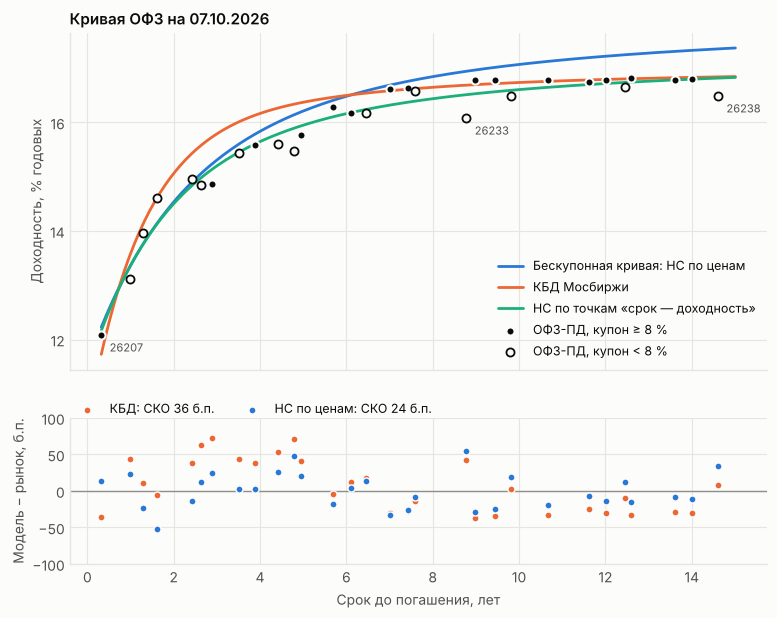

In [5]:
fig = plots.plot_curve(snap, fit, ytm_curve, kbd)

In [6]:
tenors = np.array([0.5, 1, 2, 3, 5, 7, 10, 15])
pd.DataFrame({"НС по ценам, %": fit.curve.rate(tenors) * 100,
              "КБД, %": kbd.rate(tenors) * 100,
              "Разница, б.п.": (fit.curve.rate(tenors) - kbd.rate(tenors)) * 1e4},
             index=pd.Index(tenors, name="Срок, лет")).round(2)

,"НС по ценам, %","КБД, %","Разница, б.п."
"Срок, лет",,,
0.5,12.56,12.31,24.97
1.0,13.37,13.58,-21.75
2.0,14.53,15.06,-52.69
3.0,15.31,15.79,-48.22
5.0,16.21,16.37,-16.18
7.0,16.69,16.58,10.28
10.0,17.07,16.74,33.24
15.0,17.37,16.85,52.61


**Что видно.**

* Формула КБД воспроизводит опубликованные биржей значения до 0,0001 % (это проверяет тест). Но сама КБД отклоняется от цен закрытия отдельных бумаг от −37 до +73 б.п.: у биржи свои веса, свой набор выпусков и сглаживание. Наша кривая ближе к ценам закрытия по СКО (сравнение на тех же данных, к которым она подогнана).
* **Купонный эффект.** Длинные ОФЗ со старыми низкими купонами (26233, 26238, 26240 — 6–7 %) торгуются на 30–70 б.п. *ниже* по доходности, чем новые выпуски того же срока с купоном 12–13 %. Одна кривая на все бумаги этого объяснить не может, отсюда основная часть ошибки на длинном конце.
* На длинном конце (от 7 лет) наша кривая проходит между двумя группами: старые низкокупонные выпуски она оценивает на +22 б.п. по доходности, новые высококупонные — на −18 б.п. КБД же идёт почти по старым выпускам (+6 б.п.) и на ≈ 31 б.п. ниже новых.

## 3. Риск

Для каждой бумаги аналитически:

* дюрация Маколея $D = \sum t_i\,PV_i / P$, модифицированная $D_{mod} = D/(1+y)$;
* выпуклость $C = \frac{1}{P}\sum t_i(t_i+1)\,CF_i\,(1+y)^{-t_i-2}$;
* $DV01 = D_{mod}\cdot P \cdot 0{,}0001$ — сколько рублей теряет одна бумага при росте доходности на 1 б.п.

Портфель: по 100 млн руб. в самый ликвидный выпуск рядом с каждым из сроков 1,5 / 3 / 5 / 10 / 15 лет.

In [7]:
secids = risk.pick_benchmarks(snap.table)
pf = risk.make_portfolio(snap, fit.curve, secids)
out = pf[["name", "maturity", "years", "ytm", "modified", "convexity", "dv01", "quantity", "dv01_rub", "z_spread_bp"]].copy()
out["ytm"] *= 100
out["maturity"] = out["maturity"].dt.strftime("%d.%m.%Y")
out.columns = ["Выпуск", "Погашение", "Лет", "YTM, %", "D mod", "Выпуклость", "DV01 на бумагу, руб.",
               "Штук", "DV01 позиции, руб.", "Z-спред, б.п."]
out.round(3)

,Выпуск,Погашение,Лет,"YTM, %",D mod,Выпуклость,"DV01 на бумагу, руб.",Штук,"DV01 позиции, руб.","Z-спред, б.п."
0,ОФЗ 26236,17.05.2028,1.61,14.62,1.33,2.99,0.12,110571.0,13258.53,51.50
1,ОФЗ 26242,29.08.2029,2.89,14.87,2.23,7.32,0.20,112934.0,22328.98,-25.05
2,ОФЗ 26249,16.06.2032,5.69,16.28,3.51,18.26,0.30,116289.0,35076.71,17.72
3,ОФЗ 26245,26.09.2035,8.97,16.79,4.57,32.22,0.37,123788.0,45736.03,28.72
4,ОФЗ 26254,03.10.2040,14.00,16.80,4.91,44.44,0.43,112710.0,49074.42,10.84


In [8]:
risk.summary(pf, snap).round(2).to_frame("Портфель")

,Портфель
"Стоимость, млн руб.",500.00
"DV01, тыс. руб. за 1 б.п.",165.47
"Модифицированная дюрация, лет",3.31
Выпуклость,21.04
"Доходность портфеля (IRR), %",16.26


**Сценарии.** Переоцениваем каждый платёж по сдвинутой бескупонной кривой. Чтобы без сдвига получалась ровно рыночная цена, у каждой бумаги держим постоянным её z-спред к кривой. Сдвиги задаются в эффективных годовых ставках, как котируется рынок:

| Сценарий | Сдвиг |
|---|---|
| ±100 б.п. параллельно | вся кривая |
| Рост наклона | до 1 года −50 б.п., от 10 лет +50 б.п., между ними линейно |
| Снижение наклона | до 1 года +50, от 10 лет −50 |
| ЦБ ужесточает | короткие +200, длинные +50 (так было осенью 2024) |
| ЦБ смягчает | короткие −200, длинные −50 |

In [9]:
scen = risk.scenario_pnl(pf, snap, fit.curve)
scen.round(2)   # млн руб.

name,ОФЗ 26236,ОФЗ 26242,ОФЗ 26249,ОФЗ 26245,ОФЗ 26254,Портфель
+100 б.п. параллельно,-1.31,-2.19,-3.39,-4.35,-4.56,-15.81
−100 б.п. параллельно,1.34,2.27,3.57,4.66,4.99,16.83
Рост наклона,0.58,0.68,0.18,-0.81,-1.18,-0.55
Снижение наклона,-0.57,-0.67,-0.18,0.84,1.26,0.68
ЦБ ужесточает,-2.47,-3.70,-4.48,-4.26,-4.01,-18.91
ЦБ смягчает,2.58,3.91,4.78,4.52,4.26,20.04


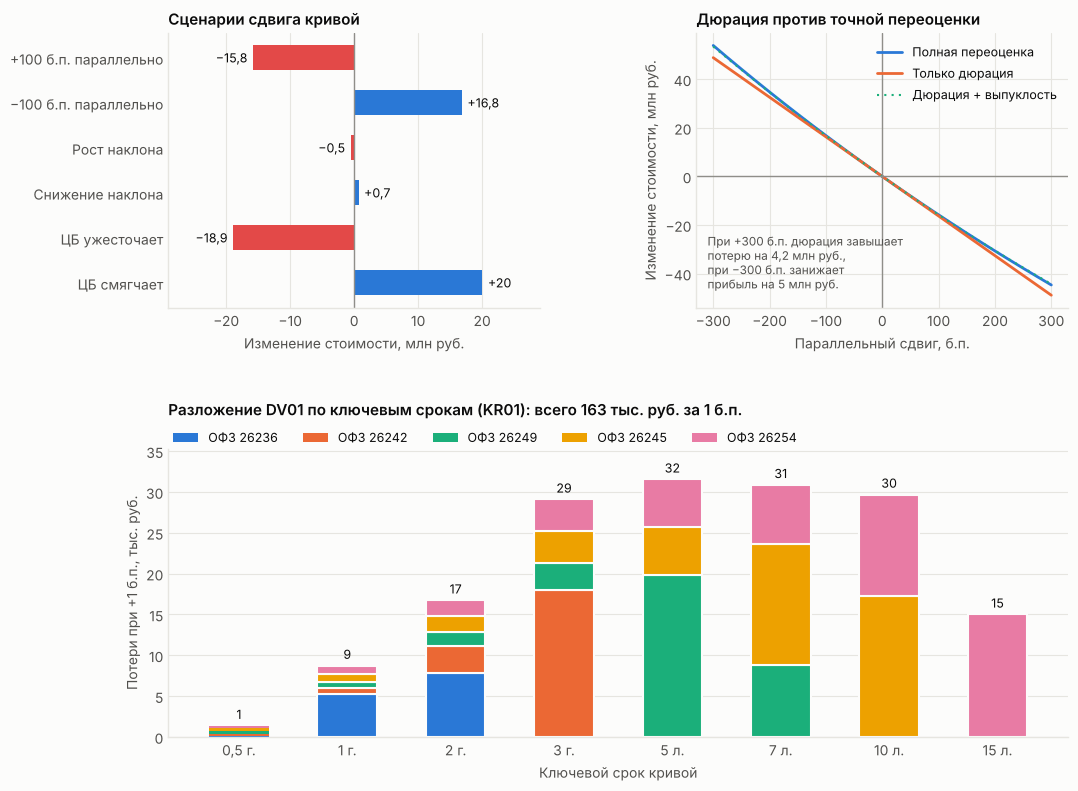

In [10]:
profile = risk.parallel_profile(pf, snap, fit.curve)
kr = risk.key_rate_dv01(pf, snap, fit.curve)
fig = plots.plot_risk(pf, scen, profile, kr)

In [11]:
print(f"Сумма KR01: {kr.values.sum():,.0f} руб.; DV01 по доходностям: {pf.dv01_rub.sum():,.0f} руб.".replace(",", " "))
(kr / 1e3).round(1)   # тыс. руб. за +1 б.п. в точке кривой

Сумма KR01: 163 022 руб.; DV01 по доходностям: 165 475 руб.


,"0,5 г.",1 г.,2 г.,3 г.,5 л.,7 л.,10 л.,15 л.
name,,,,,,,,
ОФЗ 26236,0.2,5.3,7.8,0.0,0.0,0.0,0.0,0.0
ОФЗ 26242,0.2,0.7,3.4,18.0,0.0,0.0,0.0,0.0
ОФЗ 26249,0.3,0.8,1.7,3.4,19.8,8.8,0.0,0.0
ОФЗ 26245,0.3,1.0,1.9,3.9,5.9,14.8,17.2,0.0
ОФЗ 26254,0.3,1.0,1.9,3.9,5.8,7.3,12.5,15.0


**Что видно.**

* Портфель на 500 млн руб. имеет DV01 ≈ 165 тыс. руб.: +100 б.п. по всей кривой стоят ≈ 16 млн.
* Выпуклость делает риск несимметричным: при −100 б.п. портфель зарабатывает больше, чем теряет при +100. Линейная оценка по дюрации на ±300 б.п. ошибается на 4–5 млн руб., причём сильнее при снижении ставок; поправка на выпуклость убирает почти всю ошибку.
* Самая длинная бумага портфеля (ОФЗ 26254, погашение в 2040 г.) имеет модифицированную дюрацию меньше 5 лет (дюрация Маколея — 5,7 года): при купоне 13 % и доходности ≈ 17 % основная часть стоимости приходится на ближние купоны.
* Сценарии наклона портфелю почти безразличны: риск размазан по кривой. KR01 показывает, где он сосредоточен: на участке 3–10 лет.

## 4. История: кривая вокруг решений Банка России

Окно: закрытие накануне решения (четверг) → закрытие первого торгового дня после него (понедельник). Решение объявляют в пятницу в 13:30, так что в окно попадают само решение, пресс-конференция и выходные.

Изменение считаем тремя способами: по нашей бескупонной кривой, по КБД и **без модели** — медианное изменение доходности одних и тех же бумаг по корзинам сроков.

In [12]:
reactions = [history.meeting_reaction(m, data) for m in history.EVENTS]
history.reaction_table(reactions)   # б.п.

,Ставка,НС 2 г.,НС 5 л.,НС 10 л.,КБД 2 г.,КБД 5 л.,КБД 10 л.,ОФЗ до 3 лет,ОФЗ 3–7 лет,ОФЗ от 7 лет
Заседание,,,,,,,,,,
2024-07-26,16 → 18,4,39,58,27,64,61,18,39,53
2024-10-25,19 → 21,75,60,42,71,70,54,79,62,48
2024-12-20,21 → 21,-312,-229,-132,-339,-248,-140,-307,-237,-172
2025-06-06,21 → 20,39,18,3,36,12,7,32,24,7
2025-07-25,20 → 18,-16,-14,-6,0,-8,-5,-13,-18,-7
2026-09-11,14 → 14,-1,13,17,6,13,21,-3,10,14


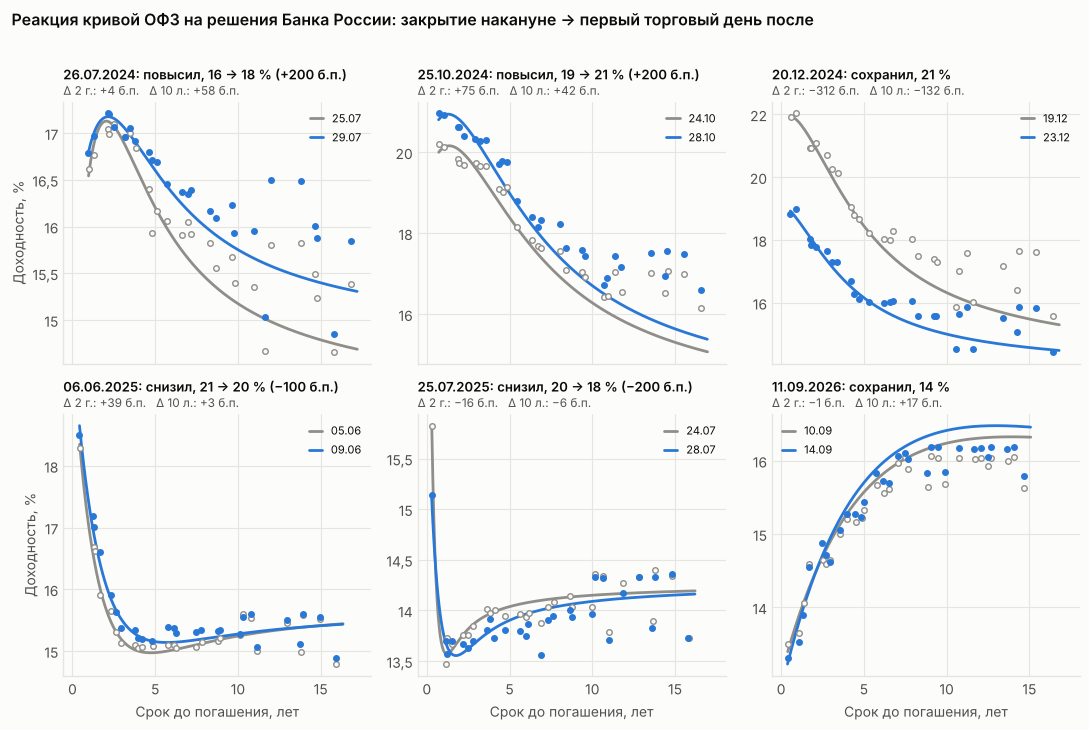

In [13]:
fig = plots.plot_meetings(reactions)

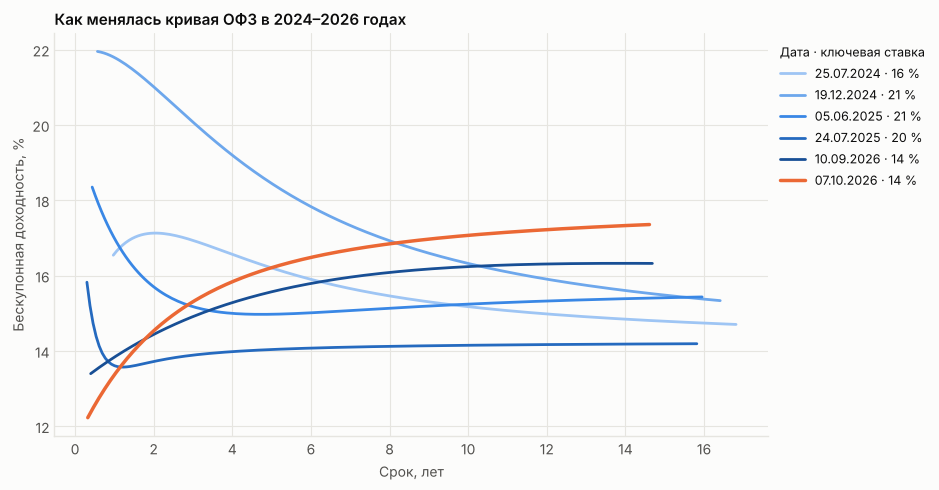

In [14]:
dates = ["2024-07-25", "2024-12-19", "2025-06-05", "2025-07-24", "2026-09-10", "2026-10-07"]
curves = []
for d in dates:
    s = MarketSnapshot.load(d, data)
    label = f"{pd.Timestamp(d):%d.%m.%Y} · {plots.num(history.key_rate_on(d), 2)} %"
    curves.append((label, s.fit_prices().curve, s.table.years.min(), s.table.years.max()))
fig = plots.plot_evolution(curves)

**Что видно.**

* **Июль 2024 (+200 б.п. до 18 %).** Короткий конец вырос лишь на ≈ 20 б.п.: повышение уже было в ценах. Сильнее распродавались длинные бумаги (+50–60 б.п.).
* **Октябрь 2024 (+200 б.п. до 21 %).** Медвежье уплощение: короткие +80 б.п., длинные +40–50. Кривая сильно инвертирована: при ключевой 21 % десятилетние ОФЗ давали около 17 %.
* **20 декабря 2024 (ставка сохранена на 21 %).** Самое сильное движение в выборке: короткие −3 п.п., длинные −1,3…−1,7 п.п. Рынок закладывал повышение, а ЦБ взял паузу.
* **Июнь 2025 (первое снижение, 21 → 20 %).** Доходности *выросли* (короткие +30–40 б.п.): снижение было ожидаемым, рынок «продал факт».
* **Июль 2025 (−200 б.п. до 18 %).** Реакция скромная, −10…−20 б.п.: снижение почти полностью было в ценах.
* **Сентябрь 2026 (ставка сохранена на 14 %).** Короткий конец на месте, длинный +15–20 б.п. К октябрю кривая стала заметно круче: короткие ставки ушли вниз (рынок, видимо, ждёт продолжения снижения ключевой), а длинные доходности выросли почти до 17 %.
* За два года кривая прошла путь от глубокой инверсии (декабрь 2024) к нормальной восходящей форме (2026).